In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import plotnine as p9

# Figure 6

In [2]:
df = pd.read_excel("Figure6.xlsx",sheet_name="metagenomes")
df['env_note'].value_counts()
df["relative_abundance"] = (df["relative_abundance"]/100)
df["corrected_relabd"] = (df["corrected_relabd"]/100)
strings_to_remove = ['mouse', 'primate', 'aardvark', 'unknown', 'composter']

pattern = '|'.join(strings_to_remove)
df_filt = df[~df['env_note'].str.contains(pattern)]
df_filt["relative_abundance_log10"] = np.log10(df_filt["relative_abundance"])
df_filt["corrected_relabd_log10"] = np.log10(df_filt["corrected_relabd"])

In [3]:
medians = df_filt.groupby(["env_note", "organism"])["corrected_relabd"].median().reset_index()
newdata = {"env_note": ["ruminant hindgut", "bioreactor", "landfill"], "organism": ["OCT", "PYRU", "PYRU"], "corrected_relabd": [0, 0, 0]}
nd_df = pd.DataFrame(newdata)
medians = pd.concat([medians, nd_df], ignore_index=True)
medians.sort_values(by=["organism"],inplace=True, ascending=False)
medians.sort_values(by=["env_note"],inplace=True)

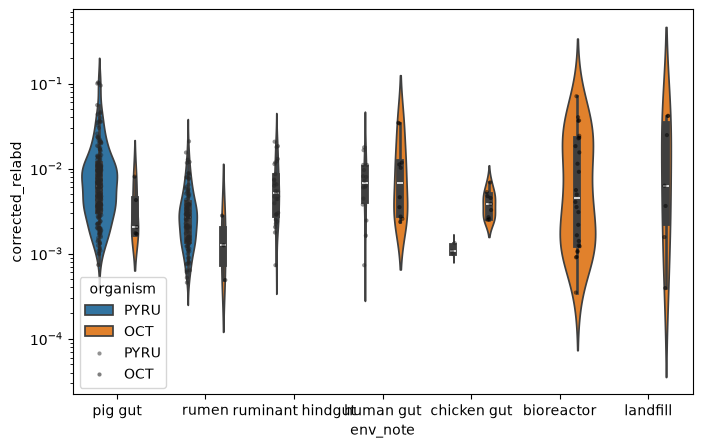

In [4]:

plt.figure(figsize=(8, 5))

ax = sns.violinplot(
    data=df_filt,
    x="env_note",
    y="corrected_relabd",
    hue="organism",
    common_norm=False,
    dodge=True,
    log_scale=True, 
    density_norm="count",
    bw_adjust=1
)

sns.stripplot(
    data=df_filt,
    x="env_note",
    y="corrected_relabd",
    hue="organism",
    dodge=True,
    jitter=0.05,
    alpha=0.5,
    size=3,
    palette='dark:k',
    log_scale=True,
    ax=ax
)

plt.savefig("oct_pyru_habitats.pdf",format="pdf")

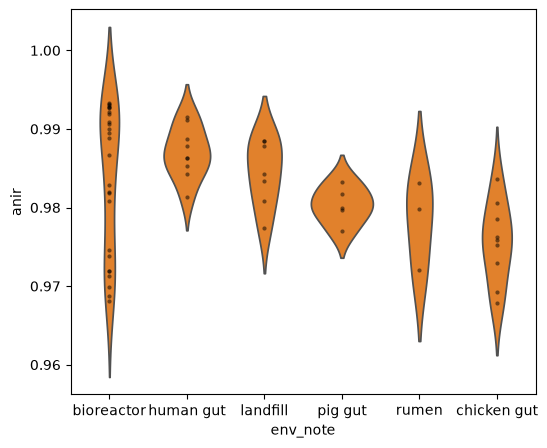

In [5]:
df_oct = df[df["organism"]=="OCT"]
plt.figure(figsize=(6, 5))

ax = sns.violinplot(
    data=df_oct,
    x="env_note",
    y="anir",
    dodge=True,
    inner=None,
    order=["bioreactor","human gut","landfill","pig gut","rumen","chicken gut"],
    color="#ff7f0e"
)

sns.stripplot(
    data=df_oct,
    x="env_note",
    y="anir",
    dodge=True,
    jitter=False,
    alpha=0.5,
    size=3,
    color="k",
    order=["bioreactor","human gut","landfill","pig gut","rumen","chicken gut"],
    ax=ax
)
plt.show()


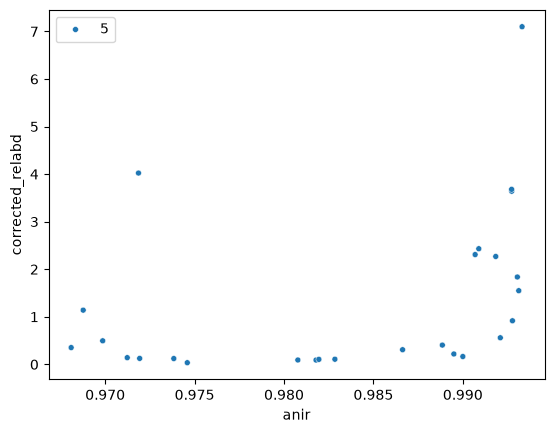

In [6]:
ax = plt.gca()

sns.scatterplot(
    data=df_oct[df_oct["env_note"] == "bioreactor"],
    x="anir",
    y=df_oct["corrected_relabd"]*100,
    size=5
)
# to colour each point, manual review of the metadata for each of the datapoints shown
# to get information on the feedstock. this was done based on SRA accessions and then
# coloured based on x, y position in adobe
plt.show()

In [7]:
df = pd.read_excel("Figure6.xlsx", sheet_name="foodwaste")

In [8]:
plotdata = df[(df["Unit"]!="Lactate") & (df["Unit"]!="Acetate GCMS")]

statdata = (
    plotdata
    .groupby(["Hour", "Media", "Unit"], as_index=False)
    .agg(
        Value_mean=("Value", "mean"),
        Value_std=("Value", "std")
    )
)

plot1 = (
    p9.ggplot(statdata, p9.aes(x="Hour",y="Value_mean",colour="Unit",fill="Unit"))    
    + p9.geom_area(stat="identity")
    + p9.facet_wrap("~Media", nrow=2, scales="free_y")
    + p9.scale_fill_cmap_d(cmap_name='viridis')
    + p9.scale_color_cmap_d(cmap_name='viridis')
    + p9.theme_matplotlib()
    + p9.ylim([0, 75])
)

In [9]:
plotdata = df[(df["Unit"]=="Lactate") | (df["Unit"]=="Acetate GCMS")]

statdata = (
    plotdata
    .groupby(["Hour", "Media", "Unit"], as_index=False)
    .agg(
        Value_mean=("Value", "mean"),
        Value_std=("Value", "std")
    )
)

plot2 = (
    p9.ggplot(statdata, p9.aes(x="Hour", y="Value_mean", colour="Unit"))
    + p9.geom_line()
    + p9.geom_errorbar(
        p9.aes(
            ymin="Value_mean - Value_std",
            ymax="Value_mean + Value_std"
        ),
        width=0.2
    )
    + p9.facet_wrap("~Media", nrow=2, scales="free_y")
    + p9.scale_fill_cmap_d(cmap_name='viridis')
    + p9.scale_color_cmap_d(cmap_name='viridis')
    + p9.theme_matplotlib()
    + p9.ylim([0, 175])
)

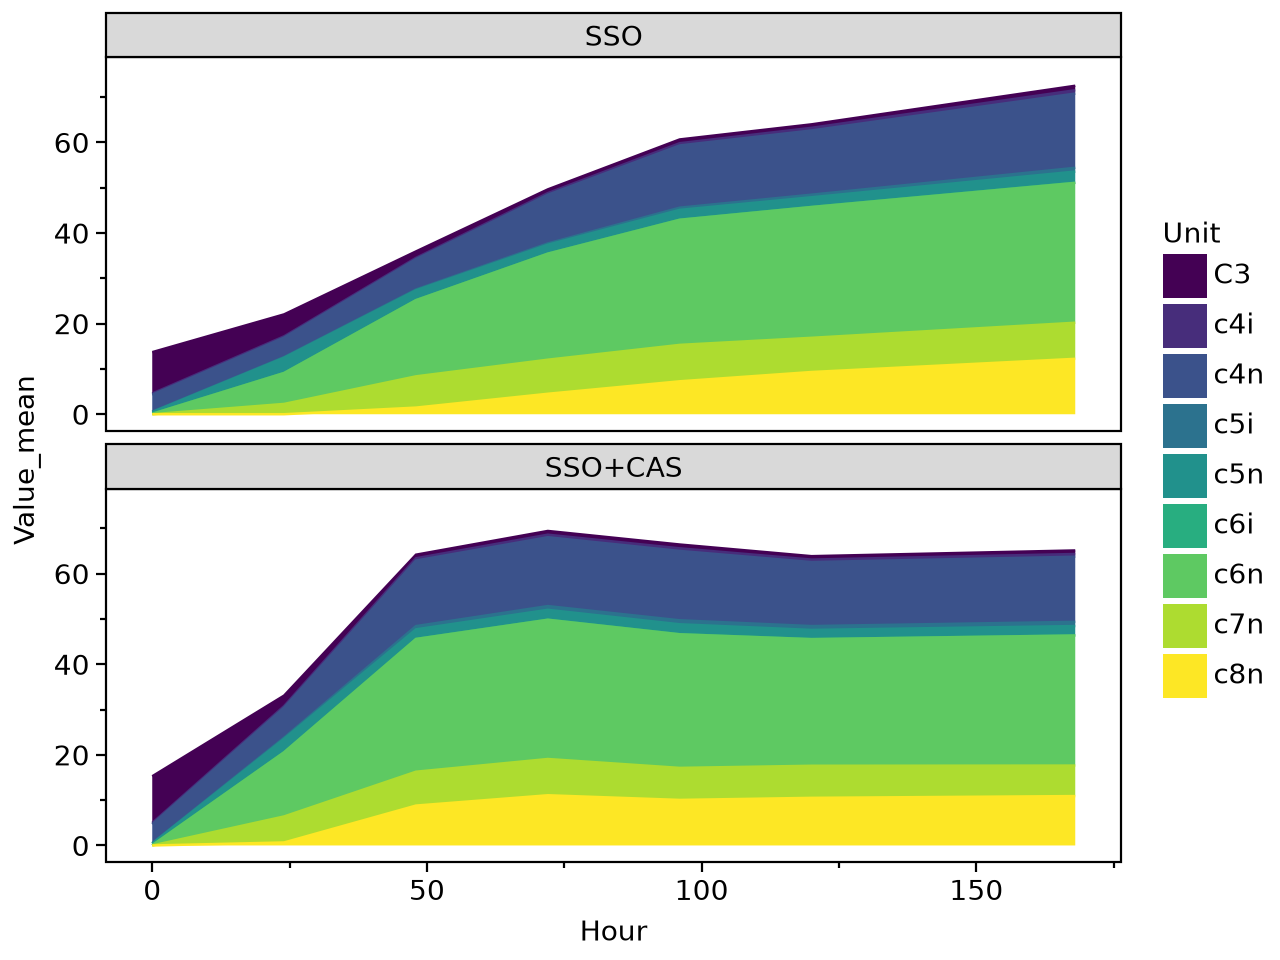

In [10]:
plot1

/Users/blindner/.venvs/notebook-env/lib/python3.13/site-packages/plotnine/guides/guides.py:211: PlotnineWarning: Cannot generate legend for the 'fill' aesthetic. Make sure you have mapped a variable to it


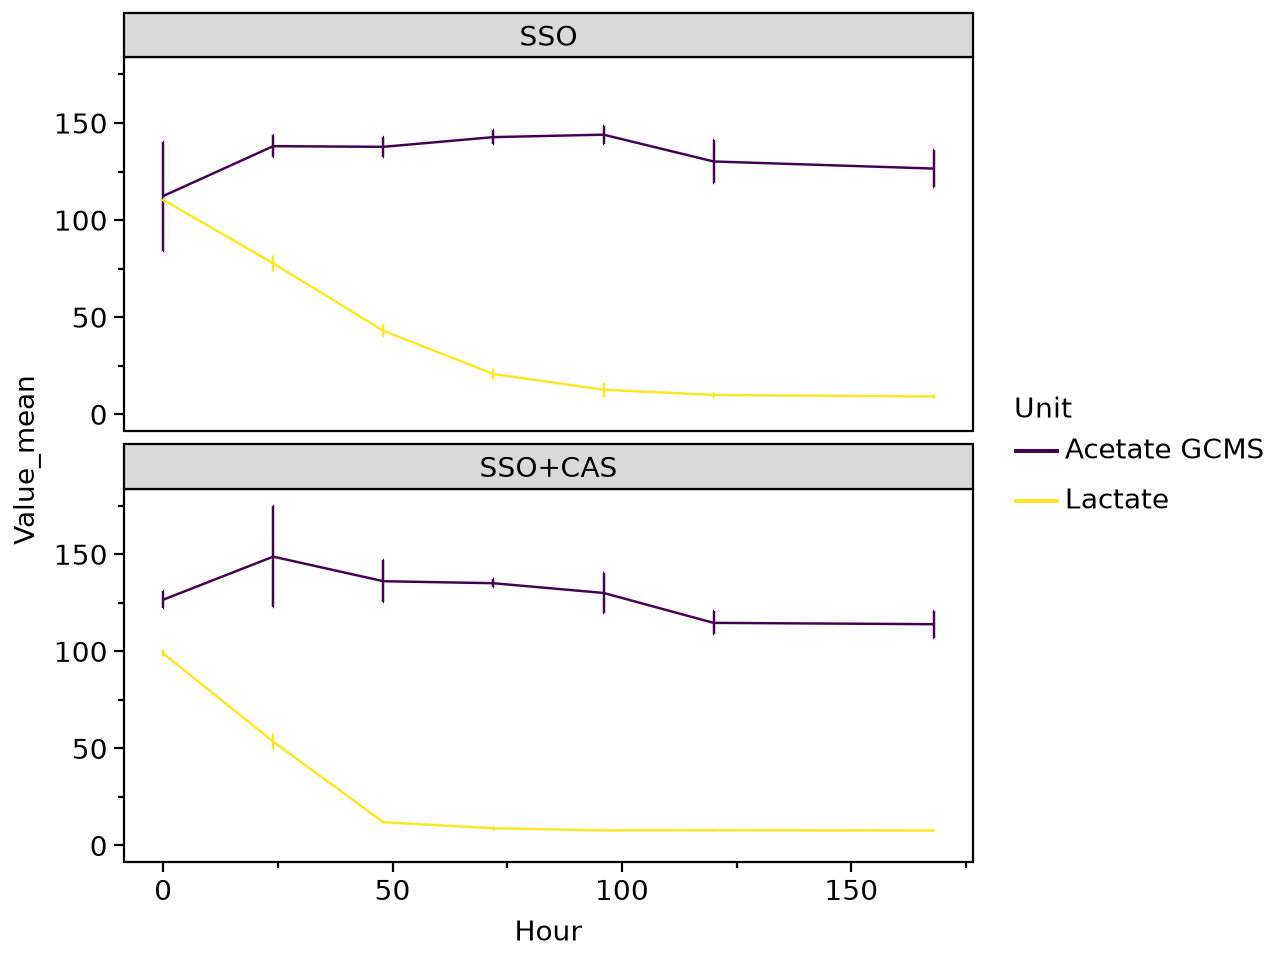

In [11]:
plot2

In [12]:
#acid whey
df = pd.read_excel("Figure6.xlsx", sheet_name="dairy")
df["kPa"] = df["PSI"] * 6.89476

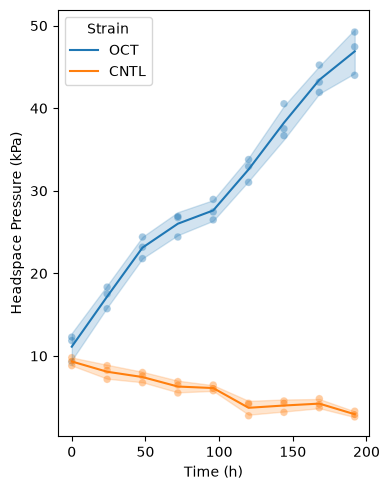

In [13]:
fig, ax = plt.subplots(figsize=(4, 5))


sns.scatterplot(data=df, x="Time", y="kPa", hue="Strain", alpha=0.4, s=30, ax=ax, legend=False)
sns.lineplot(data=df, x="Time", y="kPa", hue="Strain", errorbar="sd", ax=ax)

ax.set_xlabel("Time (h)")
ax.set_ylabel("Headspace Pressure (kPa)")
plt.tight_layout()
plt.show()

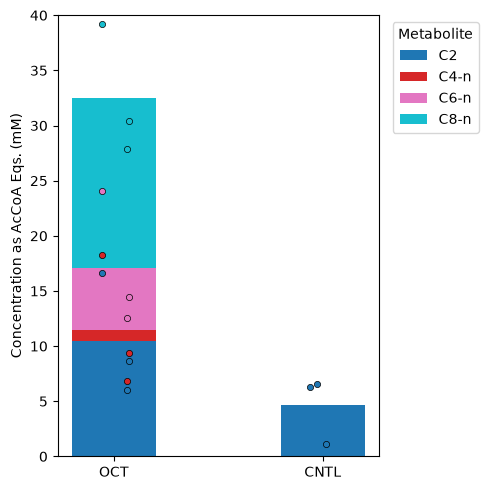

In [14]:
metabolites = ["C2", "C3", "C4-i", "C4-n", "C5-i", "C5-n", "C6-i", "C6-n", "C7-n", "C8-n"]
weights =     [1, 0, 0, 2, 0, 1, 1, 3, 2, 4]
weight_map = dict(zip(metabolites, weights))

df_final = df[df["Time"] == 192].copy()
for m in metabolites:
    df_final[m] = df_final[m] * weight_map[m]

groups = df_final["Strain"].unique()
x_pos = {g: i for i, g in enumerate(groups)}

# purge metabolites that are 0 across all groups after weighting
active_metabolites = [m for m in metabolites if df_final[m].fillna(0).sum() > 0]
colors = cm.tab10(np.linspace(0, 1, len(active_metabolites)))

fig, ax = plt.subplots(figsize=(5, 5))
bar_width, jitter_width = 0.4, 0.075

for g in groups:
    sub = df_final[df_final["Strain"] == g]
    x = x_pos[g]

    # avg as stacked bars
    means = sub[active_metabolites].mean()
    bottom = 0
    for metabolite, color in zip(active_metabolites, colors):
        val = means[metabolite] if pd.notna(means[metabolite]) else 0
        if val > 0:
            ax.bar(x, val, bottom=bottom, width=bar_width,
                   color=color, edgecolor="none",
                   label=metabolite if x == 0 else None)
        bottom += val

    # reps as stacked points
    for _, row in sub.iterrows():
        jitter = np.random.uniform(-jitter_width, jitter_width)
        bottom = 0
        for metabolite, color in zip(active_metabolites, colors):
            val = row[metabolite] if pd.notna(row[metabolite]) else 0
            top = bottom + val
            if val > 0:
                ax.scatter(x + jitter, top, color=color, edgecolor="black",
                           linewidth=0.5, s=20, zorder=3)
            bottom = top

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels(list(x_pos.keys()))
ax.set_ylabel("Concentration as AcCoA Eqs. (mM)")
ax.set_ylim(0, 40)
ax.legend(title="Metabolite", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

/var/folders/9w/814g99y92q14fd5kwlm2dc8c0000gn/T/ipykernel_76970/1733158919.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


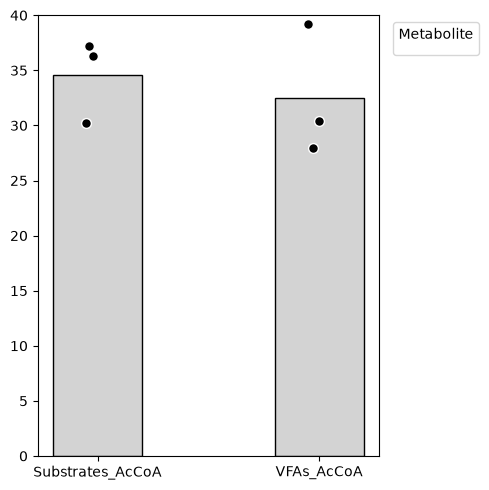

In [15]:
plotdata = df[(df["Strain"] == "OCT") & (df["Time"] == 192)].copy()
long_plotdata = plotdata.melt(
    value_vars=["Substrates_AcCoA", "VFAs_AcCoA"],
    var_name="Variable",
    value_name="AcCoA_Eqs"
)


groups = long_plotdata["Variable"].unique()
x_pos = {g: i for i, g in enumerate(groups)}

fig, ax = plt.subplots(figsize=(5, 5))


for g in groups:
    sub = long_plotdata[long_plotdata["Variable"] == g]
    x = x_pos[g]

    # mean as a bar
    mean_val = sub["AcCoA_Eqs"].mean()
    ax.bar(x, mean_val, width=bar_width, 
           color="lightgray", edgecolor="black") 

    # individual points, jittered
    jitter = np.random.uniform(-jitter_width, jitter_width, size=len(sub))
    ax.scatter(x + jitter, sub["AcCoA_Eqs"], color="black", edgecolor="white",
               s=50, zorder=3)

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels(list(x_pos.keys()))
ax.set_ylim(0, 40)
ax.legend(title="Metabolite", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()